In [1]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost",
    port=5433,
    database="rossmann",
)
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM train_clean LIMIT 5", engine)
df

PostgreSQL password:  ········


,store,day_of_week,date,sales,customers,open,promo,state_holiday,school_holiday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

query = """
SELECT t.*, s.store_type, s.assortment, s.competition_distance, s.promo2
FROM train_clean t
JOIN store s ON t.store = s.store
"""
data = pd.read_sql(query, engine)
data["date"] = pd.to_datetime(data["date"])

print(data.shape)
data.head()

(844338, 13)


,store,day_of_week,date,sales,customers,open,promo,state_holiday,school_holiday,store_type,assortment,competition_distance,promo2
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,1
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,0


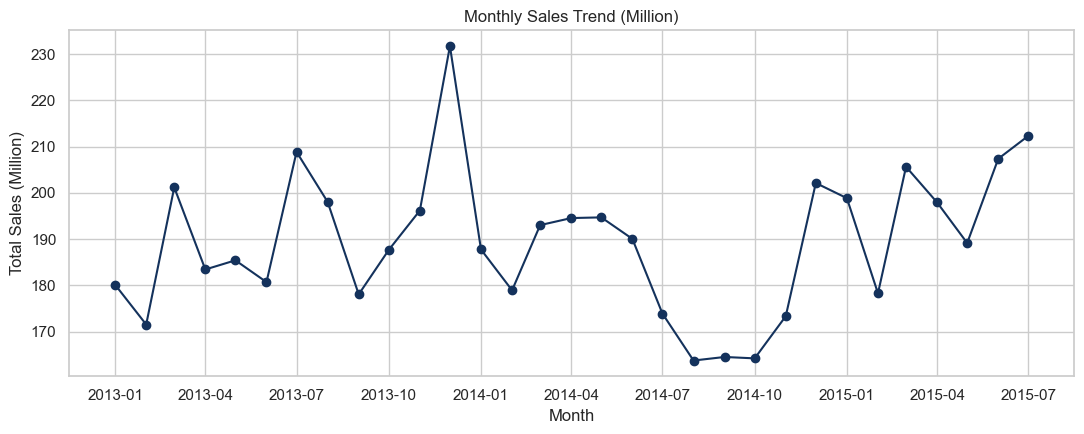

In [3]:
monthly = data.set_index("date")["sales"].resample("MS").sum() / 1e6

plt.figure(figsize=(11, 4.5))
plt.plot(monthly.index, monthly.values, marker="o", color="#14325c")
plt.title("Monthly Sales Trend (Million)")
plt.xlabel("Month")
plt.ylabel("Total Sales (Million)")
plt.tight_layout()
plt.savefig("images/01_monthly_trend.png", dpi=150)
plt.show()

In [4]:
check = data.groupby(data["date"].dt.to_period("M")).agg(
    open_stores=("store", "nunique"),
    total_sales_m=("sales", lambda x: round(x.sum() / 1e6, 1)),
    avg_sales_per_store_day=("sales", "mean"),
).round(0)
check

,open_stores,total_sales_m,avg_sales_per_store_day
date,,,
2013-01,1112,180.0,6241.0
2013-02,1112,172.0,6429.0
2013-03,1112,201.0,7213.0
2013-04,1112,183.0,6580.0
2013-05,1113,185.0,7077.0
2013-06,1113,181.0,6468.0
2013-07,1115,209.0,6924.0
2013-08,1115,198.0,6596.0
2013-09,1115,178.0,6364.0


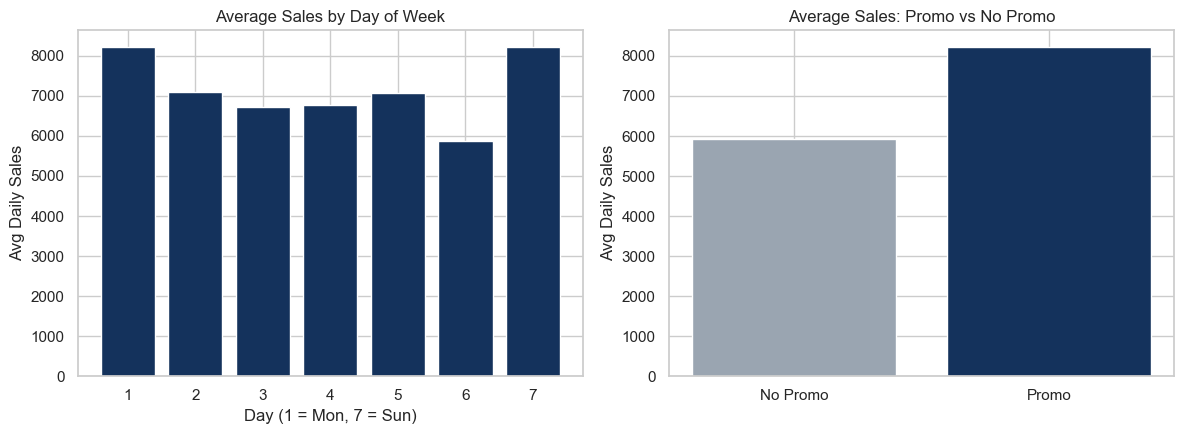

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Weekday pattern (1 = Monday, 7 = Sunday)
wk = data.groupby("day_of_week")["sales"].mean()
axes[0].bar(wk.index, wk.values, color="#14325c")
axes[0].set_title("Average Sales by Day of Week")
axes[0].set_xlabel("Day (1 = Mon, 7 = Sun)")
axes[0].set_ylabel("Avg Daily Sales")

# Promo vs non-promo
pr = data.groupby("promo")["sales"].mean()
axes[1].bar(["No Promo", "Promo"], pr.values, color=["#9aa5b1", "#14325c"])
axes[1].set_title("Average Sales: Promo vs No Promo")
axes[1].set_ylabel("Avg Daily Sales")

plt.tight_layout()
plt.savefig("images/02_weekday_promo.png", dpi=150)
plt.show()

In [6]:
wk_check = data.groupby("day_of_week").agg(
    open_store_days=("store", "size"),
    stores_open=("store", "nunique"),
    avg_sales=("sales", "mean"),
).round(0)
wk_check

,open_store_days,stores_open,avg_sales
day_of_week,,,
1,137557,1115,8216.0
2,143955,1115,7088.0
3,141922,1115,6729.0
4,134626,1115,6768.0
5,138633,1115,7073.0
6,144052,1115,5875.0
7,3593,33,8225.0


In [7]:
jun = set(data[(data["date"] >= "2014-06-01") & (data["date"] < "2014-07-01")]["store"])
aug = set(data[(data["date"] >= "2014-08-01") & (data["date"] < "2014-09-01")]["store"])
gap = sorted(jun - aug)
stores = data.drop_duplicates("store")[["store", "store_type"]]
gap_df = stores[stores["store"].isin(gap)]

print(len(gap), "stores missing in Aug 2014")
print(gap[:15])

summary = pd.DataFrame({
    "missing": gap_df["store_type"].value_counts(),
    "total": stores["store_type"].value_counts(),
}).fillna(0)
summary["missing_pct"] = (100 * summary["missing"] / summary["total"]).round(1)
summary

181 stores missing in Aug 2014
[13, 20, 22, 32, 36, 41, 46, 51, 52, 58, 72, 76, 81, 89, 99]


,missing,total,missing_pct
store_type,,,
a,84,602,14.0
d,81,348,23.3
c,15,148,10.1
b,1,17,5.9


In [8]:
df = data.sort_values(["store", "date"]).reset_index(drop=True)

# Calendar-based lags (store closed days = NaN, rows shift panna maatom)
base = df[["store", "date", "sales"]]
for lag in [7, 14, 21, 28]:
    tmp = base.copy()
    tmp["date"] = tmp["date"] + pd.Timedelta(days=lag)
    tmp = tmp.rename(columns={"sales": f"lag_{lag}"})
    df = df.merge(tmp, on=["store", "date"], how="left")

df["roll_mean_4w"] = df[["lag_7", "lag_14", "lag_21", "lag_28"]].mean(axis=1)

# Calendar features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["week"] = df["date"].dt.isocalendar().week.astype(int)

# Encode categories
df["state_holiday"] = df["state_holiday"].astype(str).map({"0": 0, "a": 1, "b": 2, "c": 3}).fillna(0)
df["store_type"] = df["store_type"].map({"a": 0, "b": 1, "c": 2, "d": 3})
df["assortment"] = df["assortment"].map({"a": 0, "b": 1, "c": 2})
df["competition_distance"] = df["competition_distance"].fillna(df["competition_distance"].median())

df.shape

(844338, 22)

In [9]:
cutoff = df["date"].max() - pd.Timedelta(days=41)   # last 6 weeks = test
train = df[df["date"] < cutoff]
test = df[df["date"] >= cutoff]
print(train.shape, test.shape, cutoff.date())

# Baseline: "same weekday last week" (lag_7)
m = test["lag_7"].notna()
err = (test.loc[m, "sales"] - test.loc[m, "lag_7"]).abs()
print("Baseline MAE :", round(err.mean()))
print("Baseline MAPE:", round((err / test.loc[m, "sales"]).mean() * 100, 1), "%")

(804056, 22) (40282, 22) 2015-06-20
Baseline MAE : 2189
Baseline MAPE: 32.1 %


In [10]:
import numpy as np
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

features = [
    "store", "day_of_week", "promo", "state_holiday", "school_holiday",
    "store_type", "assortment", "competition_distance", "promo2",
    "year", "month", "day", "week",
    "lag_7", "lag_14", "lag_21", "lag_28", "roll_mean_4w",
]

# Validation = last 6 weeks of train (test ah early stopping ku use pannala)
val_cut = cutoff - pd.Timedelta(days=41)
tr = train[train["date"] < val_cut]
va = train[train["date"] >= val_cut]

model = LGBMRegressor(
    n_estimators=2000, learning_rate=0.05, num_leaves=63,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1,
)
model.fit(
    tr[features], np.log1p(tr["sales"]),
    eval_set=[(va[features], np.log1p(va["sales"]))],
    callbacks=[early_stopping(50), log_evaluation(0)],
)
print("Best iteration:", model.best_iteration_)

C:\Users\chand\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[71]	valid_0's l2: 0.0200442
Best iteration: 71


In [11]:
pred = np.expm1(model.predict(test[features]))
actual = test["sales"].values

def report(name, a, p):
    mae = np.mean(np.abs(a - p))
    mape = np.mean(np.abs(a - p) / a) * 100
    print(f"{name}: MAE {mae:.0f} | MAPE {mape:.1f}%")

m = test["lag_7"].notna().values
report("Baseline (same rows)", actual[m], test["lag_7"].values[m])
report("LightGBM (same rows)", actual[m], pred[m])
report("LightGBM (all test rows)", actual, pred)

Baseline (same rows): MAE 2189 | MAPE 32.1%
LightGBM (same rows): MAE 673 | MAPE 10.0%
LightGBM (all test rows): MAE 674 | MAPE 10.0%


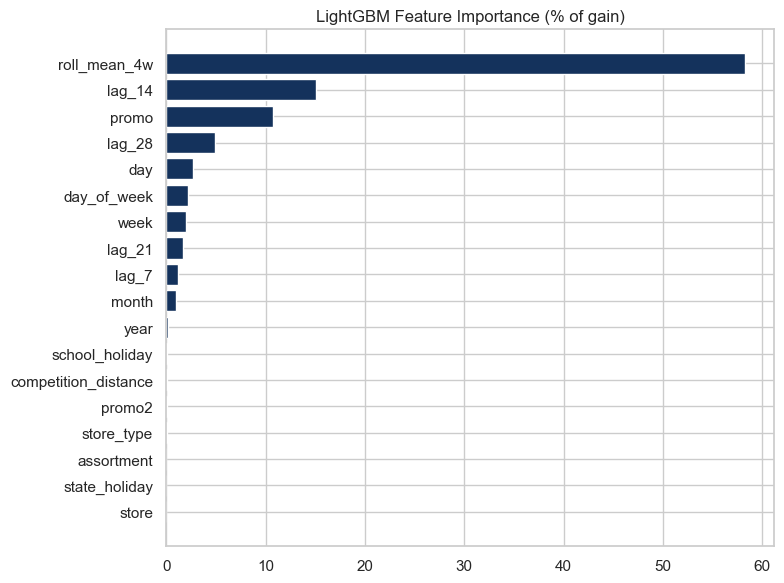

roll_mean_4w    58.3
lag_14          15.1
promo           10.7
lag_28           4.9
day              2.7
dtype: float64
store_type
a    10.3
b     8.2
c    10.0
d     9.8
Name: ape, dtype: float64
promo
0     9.9
1    10.2
Name: ape, dtype: float64


In [12]:
# 1. Feature importance
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=features)
imp = (100 * imp / imp.sum()).sort_values()
plt.figure(figsize=(8, 6))
plt.barh(imp.index, imp.values, color="#14325c")
plt.title("LightGBM Feature Importance (% of gain)")
plt.tight_layout()
plt.savefig("images/03_feature_importance.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).head(5).round(1))

# 2. Error by store type and promo
res = test[["store", "date", "store_type", "promo", "day_of_week", "sales"]].copy()
res["pred"] = pred
res["ape"] = (res["sales"] - res["pred"]).abs() / res["sales"] * 100
res["store_type"] = res["store_type"].map({0: "a", 1: "b", 2: "c", 3: "d"})
print(res.groupby("store_type")["ape"].mean().round(1))
print(res.groupby("promo")["ape"].mean().round(1))

# 3. Save predictions (Power BI ku venum)
res.to_csv("data/test_predictions.csv", index=False)

In [13]:
from scipy.stats import norm

LEAD_TIME = 7        # days (assumption)
SERVICE_LEVEL = 0.95 # assumption
z = norm.ppf(SERVICE_LEVEL)

res["error"] = res["sales"] - res["pred"]

inv = res.groupby("store").agg(
    test_days=("sales", "size"),
    avg_daily_forecast=("pred", "mean"),
    error_std=("error", "std"),
).reset_index()
inv = inv[inv["test_days"] >= 20].copy()   # romba kammi days irukkura stores remove

inv["lead_time_demand"] = inv["avg_daily_forecast"] * LEAD_TIME
inv["safety_stock"] = z * inv["error_std"] * np.sqrt(LEAD_TIME)
inv["reorder_point"] = inv["lead_time_demand"] + inv["safety_stock"]
inv["safety_pct"] = 100 * inv["safety_stock"] / inv["reorder_point"]
inv = inv.round(0)

inv.to_csv("data/inventory_recommendations.csv", index=False)
print(len(inv), "stores")
print(inv[["avg_daily_forecast", "safety_stock", "reorder_point", "safety_pct"]].describe().round(0))
inv.sort_values("reorder_point", ascending=False).head(10)


1114 stores
       avg_daily_forecast  safety_stock  reorder_point  safety_pct
count              1114.0        1114.0         1114.0      1114.0
mean               6971.0        3678.0        52474.0         7.0
std                2239.0        2035.0        16863.0         2.0
min                2837.0        1223.0        21082.0         4.0
25%                5484.0        2688.0        41242.0         6.0
50%                6668.0        3350.0        50112.0         7.0
75%                8010.0        4172.0        60131.0         8.0
max               19713.0       43310.0       147927.0        37.0


,store,test_days,avg_daily_forecast,error_std,lead_time_demand,safety_stock,reorder_point,safety_pct
1113,1114,36,19713.0,2282.0,137994.0,9933.0,147927.0,7.0
261,262,42,18750.0,3369.0,131251.0,14661.0,145912.0,10.0
841,842,36,18599.0,2737.0,130190.0,11912.0,142102.0,8.0
816,817,36,18648.0,1891.0,130537.0,8230.0,138767.0,6.0
250,251,36,18028.0,2183.0,126193.0,9501.0,135695.0,7.0
787,788,36,17305.0,1704.0,121133.0,7415.0,128548.0,6.0
755,756,36,16251.0,2901.0,113760.0,12625.0,126386.0,10.0
512,513,36,16769.0,1693.0,117382.0,7370.0,124752.0,6.0
561,562,42,16885.0,1183.0,118198.0,5149.0,123347.0,4.0
697,698,36,16430.0,1899.0,115013.0,8266.0,123278.0,7.0


In [14]:
t = test.copy()
t_on, t_off = t.copy(), t.copy()
t_on["promo"], t_off["promo"] = 1, 0

on = np.expm1(model.predict(t_on[features]))
off = np.expm1(model.predict(t_off[features]))

print(f"Model-estimated promo uplift: {(on.sum() - off.sum()) / off.sum() * 100:.1f}%")

tmp = pd.DataFrame({"store_type": t["store_type"].map({0: "a", 1: "b", 2: "c", 3: "d"}), "on": on, "off": off})
g = tmp.groupby("store_type")[["on", "off"]].sum()
print((100 * (g["on"] - g["off"]) / g["off"]).round(1))

Model-estimated promo uplift: 30.6%
store_type
a    30.4
b    21.1
c    31.2
d    31.6
dtype: float64


In [15]:
daily = data.groupby("date").agg(
    total_sales=("sales", "sum"),
    open_stores=("store", "nunique"),
    promo_share=("promo", "mean"),
).reset_index()
daily.to_csv("data/daily_sales.csv", index=False)

store_sum = data.groupby(["store", "store_type", "assortment"]).agg(
    total_sales=("sales", "sum"),
    avg_daily_sales=("sales", "mean"),
    avg_customers=("customers", "mean"),
).round(0).reset_index()
store_sum.to_csv("data/store_summary.csv", index=False)

print(daily.shape, store_sum.shape)

(942, 4) (1115, 6)


In [16]:
import os
os.makedirs("app", exist_ok=True)

# 1. Model save
model.booster_.save_model("app/model.txt")

# 2. Last 35 days sales (lag features ku)
last_date = df["date"].max()
hist = df.loc[df["date"] > last_date - pd.Timedelta(days=35), ["store", "date", "sales"]]
hist.to_csv("app/history.csv", index=False)

# 3. Store info (+ Sunday la open aagura stores)
sun = set(df.loc[df["day_of_week"] == 7, "store"])
info = df.drop_duplicates("store")[["store", "store_type", "assortment", "competition_distance", "promo2"]].copy()
info["opens_sunday"] = info["store"].isin(sun).astype(int)
info.to_csv("app/store_info.csv", index=False)

# 4. Safety stock
inv[["store", "safety_stock"]].to_csv("app/safety.csv", index=False)

print(last_date.date(), hist.shape, info.shape, int(info["opens_sunday"].sum()))
print(os.listdir("app"))

2015-07-31 (33565, 3) (1115, 6) 33
['app.py', 'history.csv', 'model.txt', 'safety.csv', 'store_info.csv']
